# Módulo 0 — Carga de datos (PH2)

| | |
|---|---|
| **Responde** | Contextualización: características de las imágenes y del dataset |
| **Código** | `carga_de_datos.py` (en esta misma carpeta) |
| **Recibe** | los archivos de `datos/PH2Dataset/` |
| **Devuelve** | un `Caso` por imagen (ver `carga_de_datos.py`) |
| **Responsable** | _completar_ |

> Las funciones se programan en `carga_de_datos.py`. Este cuaderno sólo las llama, grafica y discute.
> Para guardar una figura para el informe: `graficos.guardar_figura(fig, "nombre")`.
> Para comprobar el módulo: `python main.py --revisar` desde la carpeta del repo.

In [1]:
# Permite usar el código de las otras carpetas del repo
import sys
sys.path.insert(0, "../..")

# Recarga los cambios que hagas en los archivos .py sin reiniciar el cuaderno
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from modulos.m0_carga_de_datos import carga_de_datos
from modulos.herramientas import graficos, lesion_de_prueba
from modulos.herramientas.procesamiento_completo import procesar, procesar_todos

graficos.aplicar_estilo()

## 1. Formato de la base

- [x] ¿Cómo viene organizada la descarga? (carpetas, nombres, formato .bmp, tamaño, profundidad de bits)
- [x] ¿Cómo están codificadas las anotaciones en `PH2_dataset.txt`? Anotar acá la equivalencia de cada código.

**Organización** (`datos/PH2Dataset/`, no se sube al repo):

```
PH2 Dataset images/IMDxxx/
├── IMDxxx_Dermoscopic_Image/IMDxxx.bmp    imagen RGB, 8 bits por canal
├── IMDxxx_lesion/IMDxxx_lesion.bmp        máscara de la lesión (binaria)
└── IMDxxx_roi/IMDxxx_Rn_LabelK.bmp        máscaras de color (sólo en 27 imágenes; K = código de color)
PH2_dataset.txt / PH2_dataset.xlsx          anotaciones (el .txt está en latin-1)
```

**Codificación de `PH2_dataset.txt`** (leyendas al final del archivo):

| Columna | Códigos |
|---|---|
| Diagnóstico clínico | 0 = nevo común, 1 = nevo atípico, 2 = melanoma (el histológico está casi siempre vacío: no se usa) |
| Asimetría | 0, 1 o 2 ejes asimétricos |
| Red de pigmento, puntos/glóbulos | A = ausente, T = típica, AT = atípica |
| Estrías, regresión, velo | A = ausente, P = presente |
| Colores | 1 blanco, 2 rojo, 3 marrón claro, 4 marrón oscuro, 5 azul grisáceo, 6 negro (separados por espacios) |

In [2]:
# Contenido de la carpeta de una imagen y características de los archivos
carpeta = carga_de_datos.CARPETA_IMAGENES / "IMD002"
for archivo in sorted(carpeta.rglob("*.bmp")):
    print(archivo.relative_to(carga_de_datos.CARPETA_IMAGENES))

from skimage import io
img = io.imread(carpeta / "IMD002_Dermoscopic_Image" / "IMD002.bmp")
masc = io.imread(carpeta / "IMD002_lesion" / "IMD002_lesion.bmp")
print(f"\nimagen: {img.shape}, {img.dtype}   máscara: {masc.shape}, {masc.dtype}")

con_roi = [p.name for p in carga_de_datos.CARPETA_IMAGENES.iterdir() if any(p.glob("*_roi/*.bmp"))]
print(f"imágenes con máscaras de color: {len(con_roi)}")

IMD002\IMD002_Dermoscopic_Image\IMD002.bmp
IMD002\IMD002_lesion\IMD002_lesion.bmp
IMD002\IMD002_roi\IMD002_R1_Label4.bmp
IMD002\IMD002_roi\IMD002_R2_Label3.bmp

imagen: (572, 765, 3), uint8   máscara: (572, 765), bool
imágenes con máscaras de color: 27


## 2. Tabla de anotaciones

`leer_tabla_ph2()` tiene que devolver las columnas que pide su docstring.

In [3]:
tabla = carga_de_datos.leer_tabla_ph2()
tabla.head()

,nombre,diagnostico,asimetria,red_pigmento,puntos_globulos,estrias,regresion,velo,colores
0,IMD003,0,0,False,False,False,False,False,marron_oscuro
1,IMD009,0,0,False,False,False,False,False,marron_claro
2,IMD016,0,0,False,True,False,False,False,marron_claro marron_oscuro
3,IMD022,0,0,False,False,False,False,False,marron_claro
4,IMD024,0,0,False,False,False,False,False,marron_claro marron_oscuro


## 3. Descripción del dataset (va a Materiales y métodos)

- [x] Cantidad por diagnóstico, por asimetría, por cantidad de colores y por D adaptado.
- [x] Ejemplos: una imagen de cada diagnóstico con su máscara (figura para el informe).

In [4]:
diag = tabla["diagnostico"].map(carga_de_datos.DIAGNOSTICOS).rename("diagnóstico")
tabla["C_derm"] = tabla["colores"].str.split().str.len()
tabla["D_derm"] = tabla[list(carga_de_datos.ESTRUCTURAS)].sum(axis=1)

print("Por diagnóstico:", tabla["diagnostico"].value_counts().sort_index().to_dict(), "\n")
for col, titulo in [("asimetria", "Asimetría (A del dermatólogo)"),
                    ("C_derm", "Cantidad de colores (C)"),
                    ("D_derm", "Estructuras presentes (D adaptado)")]:
    print(titulo)
    print(pd.crosstab(diag, tabla[col]), "\n")

print("Estructuras presentes por diagnóstico")
print(tabla.groupby(diag)[list(carga_de_datos.ESTRUCTURAS)].sum())

Por diagnóstico: {0: 80, 1: 80, 2: 40} 

Asimetría (A del dermatólogo)
asimetria      0   1   2
diagnóstico             
melanoma       5   2  33
nevo atípico  35  27  18
nevo común    77   2   1 

Cantidad de colores (C)
C_derm         1   2   3   4  5
diagnóstico                    
melanoma       0  13  11  13  3
nevo atípico  20  51   9   0  0
nevo común    34  43   3   0  0 

Estructuras presentes (D adaptado)
D_derm         0   1   2   3   4  5
diagnóstico                        
melanoma       0   2  12  10  11  5
nevo atípico   1  28  40   9   2  0
nevo común    28  52   0   0   0  0 

Estructuras presentes por diagnóstico
              red_pigmento  puntos_globulos  estrias  regresion  velo
diagnóstico                                                          
melanoma                39               22       13         21    30
nevo atípico            77               40       16          4     6
nevo común               0               51        1          0     0


In [5]:
# Tamaños de las imágenes (no es fijo) y fracción de la imagen que ocupa la lesión
casos = [carga_de_datos.cargar_caso(n, tabla) for n in tabla["nombre"]]   # tarda unos segundos
tamanos = pd.Series([f"{c.imagen.shape[1]}x{c.imagen.shape[0]}" for c in casos])
print(f"{tamanos.nunique()} tamaños distintos; los más comunes:", tamanos.value_counts().head(3).to_dict())
fraccion = pd.Series([c.mascara_ref.mean() for c in casos])
print(f"fracción ocupada por la lesión: mín {fraccion.min():.2f}, mediana {fraccion.median():.2f}, máx {fraccion.max():.2f}")
toca_borde = sum(c.mascara_ref[[0, -1], :].any() or c.mascara_ref[:, [0, -1]].any() for c in casos)
print(f"lesiones que tocan el borde de la imagen: {toca_borde}")

24 tamaños distintos; los más comunes: {'767x576': 94, '768x576': 31, '765x573': 12}
fracción ocupada por la lesión: mín 0.03, mediana 0.23, máx 0.98
lesiones que tocan el borde de la imagen: 50


WindowsPath('C:/Users/Facu/Desktop/1er Cuatri 4to (Bioingenieria)/Procesamiento de Señales e Imagenes Biomedicas/TP Imagenes - Final/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m0_ejemplos.pdf')

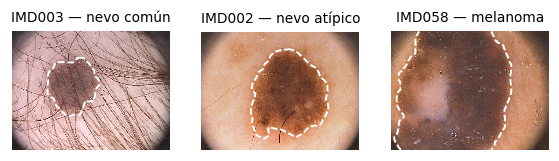

In [6]:
# Figura para el informe: un ejemplo de cada diagnóstico con el contorno de la máscara de PH2
fig, ax = plt.subplots(1, 3)
for a, nombre in zip(ax, ["IMD003", "IMD002", "IMD058"]):
    caso = carga_de_datos.cargar_caso(nombre, tabla)
    graficos.mostrar(a, caso.imagen, f"{nombre} — {carga_de_datos.DIAGNOSTICOS[caso.diagnostico]}")
    graficos.contorno(a, caso.mascara_ref, referencia=True)
graficos.guardar_figura(fig, "m0_ejemplos")

**Observaciones de la figura:** el contorno de PH2 sigue el borde de la lesión y los colores se ven naturales (imagen y máscara bien cargadas). IMD003 tiene muchos pelos sobre la lesión (caso de prueba para M1), IMD058 toca el borde de la imagen (cuidado con la viñeta en M1 y con A y B en M4, porque la lesión no se ve completa) y la intensidad de la viñeta cambia mucho entre imágenes.

## 4. Alcance acotado (devolución del anteproyecto)

- [x] Decidir qué imágenes entran y por qué (`seleccionar_subconjunto`). Dejar la justificación acá y en el informe.

### Decisiones de M0

- **Alcance:** se usan las 200 imágenes de PH2 (`DIAGNOSTICOS_INCLUIDOS = (0, 1, 2)`). El recorte que pidió la devolución se aplica en los objetivos: la comparación del algoritmo sobre imágenes comprimidas con JPEG queda como objetivo de máxima.
- **Etiqueta:** sospechosa = nevo atípico o melanoma (120); no sospechosa = nevo común (80). Es la pregunta del anteproyecto: distinguir las lesiones que ameritan control de los lunares comunes.
- **Criterio D adaptado:** cantidad de estructuras presentes según el dermatólogo (0 a 5). La red de pigmento cuenta **sólo si es atípica**: en PH2 las 200 imágenes tienen red (típica o atípica), así que su presencia no distingue nada. El resto de las estructuras cuentan si no son "A".
- **Tamaño:** las imágenes no tienen tamaño fijo (24 tamaños distintos); ningún módulo debe asumir 768 × 560.
- **Partición:** 70/30 estratificada por diagnóstico, semilla 0: 140 de entrenamiento y 60 de prueba.

In [7]:
# Comprobación de las decisiones
sub = carga_de_datos.seleccionar_subconjunto(tabla)
print(f"imágenes en el alcance: {len(sub)}")
print(f"sospechosas: {(sub['diagnostico'] > 0).sum()}   no sospechosas: {(sub['diagnostico'] == 0).sum()}")
print("\nRed de pigmento atípica por diagnóstico (lo que justifica la decisión del criterio D):")
print(tabla.groupby(diag)["red_pigmento"].agg(["sum", "count"]).rename(columns={"sum": "con red atípica", "count": "total"}))
print("\nD adaptado medio por diagnóstico:", tabla.groupby(diag)["D_derm"].mean().round(2).to_dict())

imágenes en el alcance: 200
sospechosas: 120   no sospechosas: 80

Red de pigmento atípica por diagnóstico (lo que justifica la decisión del criterio D):
              con red atípica  total
diagnóstico                         
melanoma                   39     40
nevo atípico               77     80
nevo común                  0     80

D adaptado medio por diagnóstico: {'melanoma': 3.12, 'nevo atípico': 1.79, 'nevo común': 0.65}


## 5. Partición entrenamiento / prueba

Se corre **una sola vez** y se sube `datos/particion.csv` al repositorio. **Ya está generada y subida**: la primera línea queda comentada para no volver a escribirla por accidente. Sólo habría que regenerarla si cambian `DIAGNOSTICOS_INCLUIDOS`, `FRACCION_PRUEBA` o `SEMILLA` (y avisar al grupo).

In [8]:
# carga_de_datos.armar_particion(carga_de_datos.seleccionar_subconjunto(tabla))   # YA GENERADA: no volver a correr
part = carga_de_datos.leer_particion()
print(part.groupby(["conjunto", "diagnostico"]).size().unstack().assign(total=lambda d: d.sum(axis=1)))
print("\nnombres repetidos:", part["nombre"].duplicated().any())
print("imágenes de la partición que no están en PH2:", set(part["nombre"]) - set(tabla["nombre"]) or "ninguna")

diagnostico     0   1   2  total
conjunto                        
entrenamiento  56  56  28    140
prueba         24  24  12     60

nombres repetidos: False
imágenes de la partición que no están en PH2: ninguna
